Building a conversational data analysis and visualization agent with LangChain’s create_pandas_dataframe_agent and Llama 4 on IBM watsonx.ai. Enabling natural language queries over CSV data to explore trends, compare values, and generate charts and heatmaps.


### Installing required libraries

In [1]:
%%capture
!pip install --user "ibm-watsonx-ai==0.2.6"
!pip install --user "langchain==0.1.16" 
!pip install --user "langchain-ibm==0.1.4"
!pip install --user "langchain-experimental==0.0.57"
!pip install --user "matplotlib==3.8.4"
!pip install --user "seaborn==0.13.2"

### Importing required libraries


In [ ]:

def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

from ibm_watsonx_ai.foundation_models import Model
from ibm_watsonx_ai.metanames import GenTextParamsMetaNames as GenParams
from ibm_watson_machine_learning.foundation_models.extensions.langchain import WatsonxLLM

from langchain_experimental.agents.agent_toolkits import create_pandas_dataframe_agent

import matplotlib.pyplot as plt
import pandas as pd

### Load the data set



Loading the CSV dataset into a pandas DataFrame for analysis and visualization.

In [2]:
df = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/ZNoKMJ9rssJn-QbJ49kOzA/student-mat.csv"
)

In [3]:
df.head(5)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

## Load LLM


Loading llama-4-maverick-17b-128e-instruct-fp8 from IBM watsonx.ai and integrating it with LangChain’s create_pandas_dataframe_agent to support natural language analysis of the dataset.

In [ ]:
# Create a dictionary to store credential information
credentials = {
    "url"    : "https://us-south.ml.cloud.ibm.com"
}


model_id    ='meta-llama/llama-4-maverick-17b-128e-instruct-fp8'

# Initialize some watsonx.ai model parameters
params = {
        GenParams.MAX_NEW_TOKENS: 256, # The maximum number of tokens that the model can generate in a single run.
        GenParams.TEMPERATURE: 0,   # A parameter that controls the randomness of the token generation. A lower value makes the generation more deterministic, while a higher value introduces more randomness.
    }
project_id  = "skills-network" 
space_id    = None
verify      = False

# Launch a watsonx.ai model
model = Model(
    model_id=model_id, 
    credentials=credentials, 
    params=params, 
    project_id=project_id, 
    space_id=space_id, 
    verify=verify
)

# Integrate the watsonx.ai model with the langchain framework
llm = WatsonxLLM(model = model)

agent = create_pandas_dataframe_agent(
    llm,
    df,
    verbose=False,
    return_intermediate_steps=True,  
    agent_executor_kwargs={"handle_parsing_errors": True},
    prefix="You are a pandas agent. Always respond using Action/Action Input/Final Answer format. Never output raw data directly."
)

## API Disclaimer


In [ ]:


credentials = {
    "url"    : "https://us-south.ml.cloud.ibm.com",
    "api_key": "api key here"
}

model = Model(
    model_id=model_id, 
    credentials=credentials, 
    params=params, 
    project_id=project_id, 
    space_id=space_id, 
    verify=verify
)

llm = WatsonxLLM(model = model)


Testing the agent with a simple query to count the rows in the loaded CSV dataset.

In [10]:
response = agent.invoke("how many rows of data are in this file?")

In [11]:
response['output']

'395\n```python\n# available variable: df\n```'

From the output above, the model reports that there are 395 rows of data in the file. Let's verify this count using Python code to ensure accuracy.


In [12]:
len(df)

395

In [13]:
response['intermediate_steps'][-1][0].tool_input.replace('; ', '\n')

'df.shape[0]'

Querying the agent to retrieve specific records from the CSV dataset based on natural language criteria.

In [14]:
response = agent.invoke("Give me all the data where student's age is over 18 years old.")

In [15]:
print(response)

{'input': "Give me all the data where student's age is over 18 years old.", 'output': "The data where student's age is over 18 years old has been successfully filtered and has 29 rows and 33 columns.", 'intermediate_steps': [(AgentAction(tool='python_repl_ast', tool_input="df[df['age'] > 18]", log="<|python_start|><|header_start|>assistant<|header_end|>\n\nThought: To get the data where the student's age is over 18 years old, I need to filter the DataFrame `df` based on the condition that `age` is greater than 18.\n\nAction: python_repl_ast\nAction Input: df[df['age'] > 18]"),     school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
127     GP   F   19       U     GT3       T     0     1   at_home     other   
153     GP   M   19       U     GT3       T     3     2  services   at_home   
210     GP   F   19       U     GT3       T     3     3     other     other   
247     GP   M   22       U     GT3       T     3     1  services  services   
257     GP   M   19  

In [16]:
response['intermediate_steps'][-1][0].tool_input.replace('; ', '\n')

"df[df['age'] > 18].shape"

### Plot data with natural language


Generating a bar chart with the query, “Plot the gender count with bars,” to compare the total numbers of male and female students in the dataset.

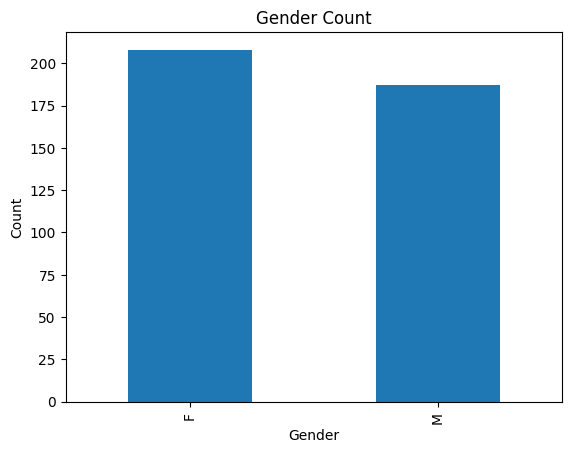

In [17]:
response = agent.invoke("Generate a bar chart to plot the gender count.")

In [18]:
print(response['intermediate_steps'][-1][0].tool_input.replace('; ', '\n'))

import matplotlib.pyplot as plt
df['sex'].value_counts().plot(kind='bar')
plt.title('Gender Count')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()


Generating a pie chart with the query, “Generate a pie chart to display the average value of Walc for each gender,” to compare average weekend alcohol consumption between male and female students.

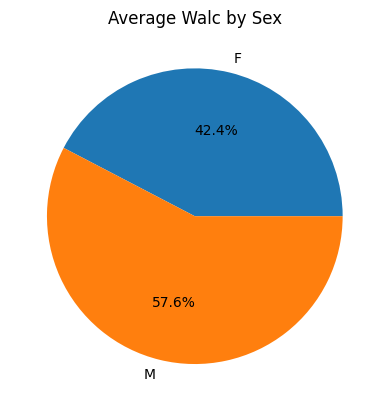

In [19]:
response = agent.invoke("Generate a pie chart to display average value of Walc for each Gender.")

Let's get the code LLM used for charting this plot.


In [20]:
print(response['intermediate_steps'][-1][0].tool_input.replace('; ', '\n'))

import matplotlib.pyplot as plt
avg_Walc = df.groupby('sex')['Walc'].mean()
plt.pie(avg_Walc, labels=avg_Walc.index, autopct='%1.1f%%')
plt.title('Average Walc by Sex')
plt.show()

Exploring the relationship between students’ free time and grades through data analysis and visualization.


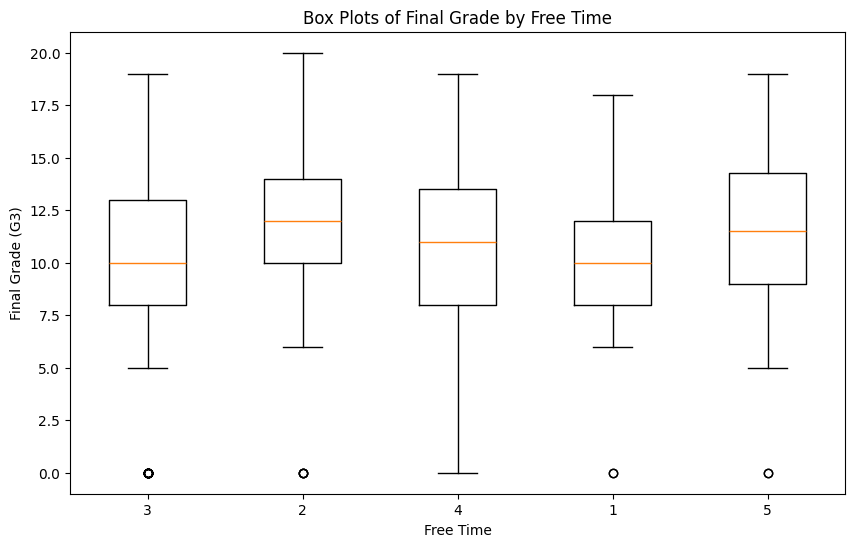

In [21]:
response = agent.invoke("Create box plots to analyze the relationship between 'freetime' (amount of free time) and 'G3' (final grade) across different levels of free time.")

In [22]:
print(response['intermediate_steps'][-1][0].tool_input.replace('; ', '\n'))

import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.boxplot([df.loc[df['freetime'] == i, 'G3'] for i in df['freetime'].unique()], labels=df['freetime'].unique())
plt.xlabel('Free Time')
plt.ylabel('Final Grade (G3)')
plt.title('Box Plots of Final Grade by Free Time')
plt.show()

Exploring the relationship between alcohol consumption and academic performance through data analysis and visualization.

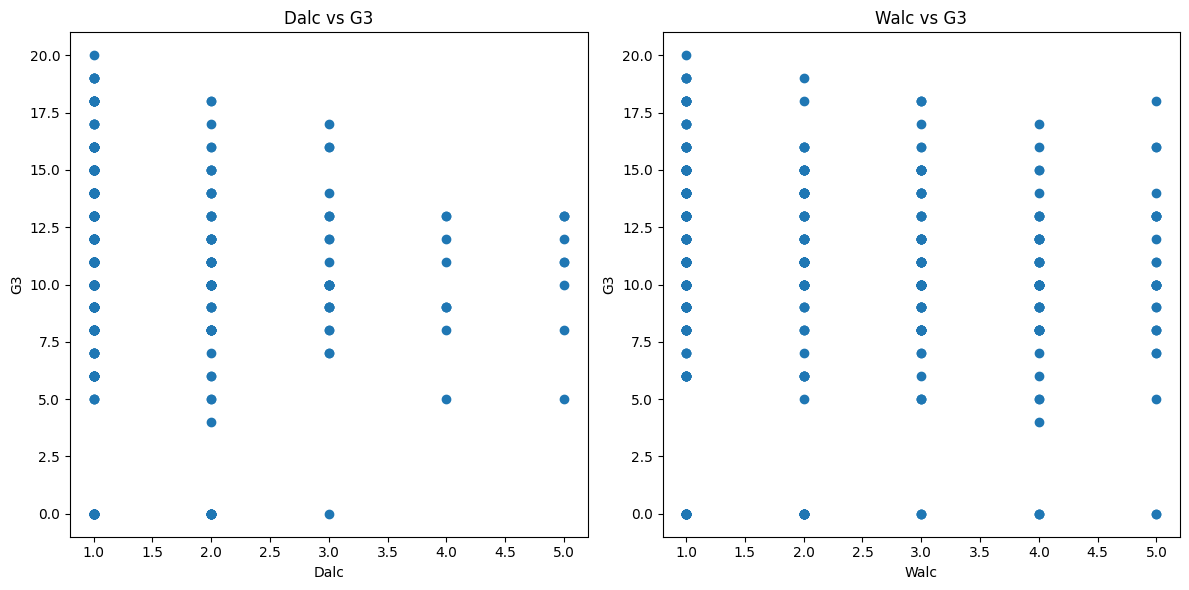

In [23]:
response = agent.invoke("Generate scatter plots to examine the correlation between 'Dalc' (daily alcohol consumption) and 'G3', and between 'Walc' (weekend alcohol consumption) and 'G3'.")

In [24]:
print(response['intermediate_steps'][-1][0].tool_input.replace('; ', '\n'))

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].scatter(df['Dalc'], df['G3'])
axs[0].set_title('Dalc vs G3')
axs[0].set_xlabel('Dalc')
axs[0].set_ylabel('G3')
axs[1].scatter(df['Walc'], df['G3'])
axs[1].set_title('Walc vs G3')
axs[1].set_xlabel('Walc')
axs[1].set_ylabel('G3')
plt.tight_layout()
plt.show()


Exploring how parental education and home internet access relate to student grades through analysis and visualization. Inspecting the agent’s execution output to identify and rerun the plotting code used to examine the relationship between absences and academic performance.

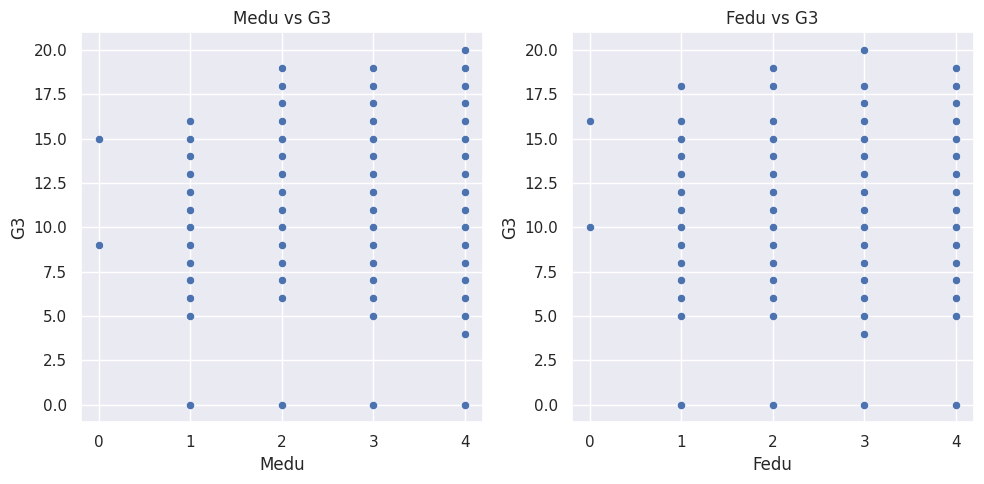

In [ ]:


response = agent.invoke(

    "Generate scatter plots showing the relationship between "
    "'Medu' (mother's education level) and 'G3' (final grade), "
    "and between 'Fedu' (father's education level) and 'G3'. "
    
)

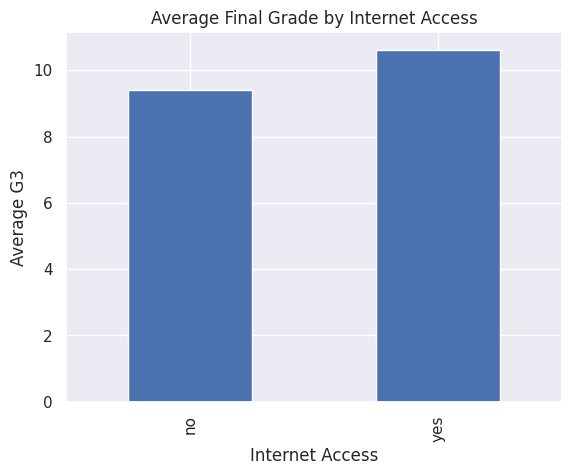

In [ ]:

response = agent.invoke("Use bar plots to compare the average final grades ('G3') of students with internet access at home versus those without ('internet' column).")

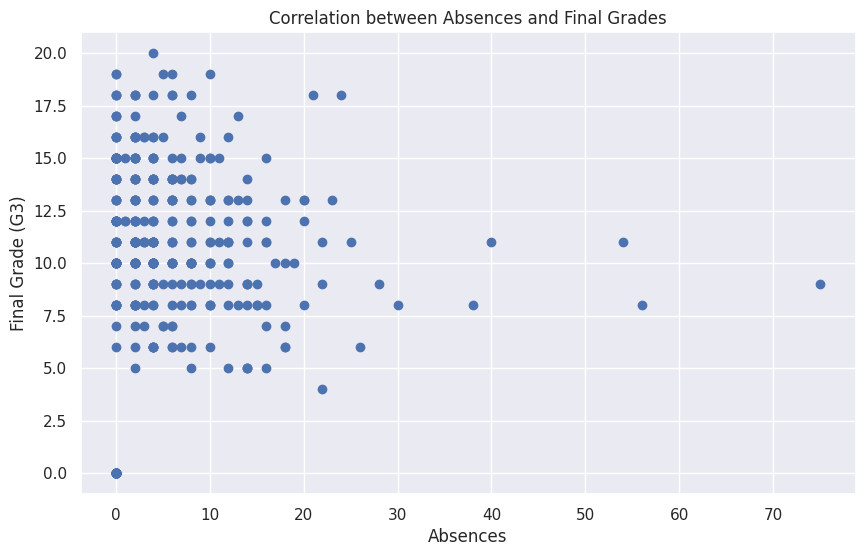

import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
 plt.scatter(df['absences'], df['G3'])
 plt.xlabel('Absences')
 plt.ylabel('Final Grade (G3)')
 plt.title('Correlation between Absences and Final Grades')
 plt.show()

In [ ]:

response = agent.invoke(
    "Plot a scatter plot showing the correlation between the number of absences('absences') and final grades('G3') of students.") 
for i in range(len(response['intermediate_steps'])):
    print(response['intermediate_steps'][i][0].tool_input.replace(';', '\n'))
